In [ ]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.baseline import evaluate, load_splits, metrics_record, train_search
from aml.config import Config
from aml.io import write_json
from aml.metrics import ranking_metrics
from aml.plotting import MUTED, NORMAL, save, set_style

try:
    import xgboost as xgb
except ImportError as e:
    raise ImportError("XGBoost is not installed. Run `pip install xgboost` in this environment, then restart the kernel.") from e

config = Config()
paths = config.paths
FIG = paths.figures_dir
SEED = config.baseline.seed

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("xgboost", xgb.__version__)

Failed to reload module 'aml.config' from file 'd:\Data Science Projects\IBM Anti-Money Laundering (AML) project\aml-collusion-detection\src\aml\config.py'
Traceback (most recent call last):
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 326, in check
    superreload(m, reload, self.old_objects)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 621, in superreload
    update_generic(old_obj, new_obj)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 407, in update_class
    if update_generic(old_obj, new_obj):
       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
xgboost 3.2.0


[autoreload of aml.config failed: Traceback (most recent call last):
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 326, in check
    superreload(m, reload, self.old_objects)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 621, in superreload
    update_generic(old_obj, new_obj)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 407, in update_class
    if update_generic(old_obj, new_obj):
       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 455, in update_generic
    update(a, b)
  File "d:\retailpulse\.venv\Lib\site-packages\IPython\extensions\autoreload.py", line 367, in update_function
    setattr(old, name, getattr(new, name))
ValueError: __init__() requires a code objec

In [29]:
features_path = paths.processed_dir / "features.parquet"
if not features_path.exists():
    raise FileNotFoundError(f"{features_path} not found. Run `python main.py clean` then `python main.py features` first.")

FEATURES = json.loads((paths.processed_dir / "feature_list.json").read_text())["features"]
format_codes = json.loads((paths.processed_dir / "payment_formats.json").read_text())
ACH = format_codes["ACH"]

splits = load_splits(features_path, FEATURES, config.baseline)
y_val, y_test = splits.y_val, splits.y_test
print(f"{len(FEATURES)} features | train (sampled) {splits.X_train.shape} | val {splits.X_val.shape} | test {splits.X_test.shape}")
splits.overview

11:38:56 | INFO | aml.baseline | 75 features | train (sampled) (611233, 75) | val (1015300, 75) | test (1015751, 75)


75 features | train (sampled) (611233, 75) | val (1015300, 75) | test (1015751, 75)


,transactions,laundering,laundering_rate,start,end
train,3046186,2296,0.0008,2022-09-01 00:00:00,2022-09-06 13:33:00
val,1015300,1083,0.0011,2022-09-06 13:34:00,2022-09-08 16:08:00
test,1015751,1143,0.0011,2022-09-08 16:09:00,2022-09-10 23:59:00


In [30]:
val = splits.meta["val"]
references = {
    "random": np.random.default_rng(SEED).random(len(val)),
    "ACH rule": (val["payment_format_code"] == ACH).astype(float).to_numpy(),
    "money flowing back (single feature)": val["pair_reverse_prior_cnt"].to_numpy(dtype=float),
}
ref_table = pd.DataFrame({name: ranking_metrics(y_val, s) for name, s in references.items()}).T
ref_table["recall_if_all_ACH_flagged"] = np.nan
ach_flag = references["ACH rule"] == 1
ref_table.loc["ACH rule", "recall_if_all_ACH_flagged"] = y_val[ach_flag].sum() / y_val.sum()
print(f"Flagging every ACH payment = {ach_flag.mean():.1%} of all payments flagged")
ref_table

Flagging every ACH payment = 12.1% of all payments flagged


,pr_auc,roc_auc,recall_if_all_ACH_flagged
random,0.0011,0.5074,NaN
ACH rule,0.0066,0.8669,0.8541
money flowing back (single feature),0.0266,0.5373,NaN


In [31]:
neg, pos = int((splits.y_train == 0).sum()), int((splits.y_train == 1).sum())
print(f"train (sampled): {pos:,} laundering vs {neg:,} normal (1 : {neg / pos:,.0f})")
print("The search below takes about 15-20 minutes on a laptop.")

train (sampled): 2,296 laundering vs 608,937 normal (1 : 265)
The search below takes about 15-20 minutes on a laptop.


In [32]:
model, best_params, search_table = train_search(splits, seed=SEED)
search_table

11:46:59 | INFO | aml.baseline | run 0: {'max_depth': 4, 'scale_pos_weight': 1.0} -> val PR-AUC 0.5874 (8.0 min)
11:52:12 | INFO | aml.baseline | run 1: {'max_depth': 6, 'scale_pos_weight': 1.0} -> val PR-AUC 0.5940 (5.2 min)
11:56:25 | INFO | aml.baseline | run 2: {'max_depth': 6, 'scale_pos_weight': 16.285467859863104} -> val PR-AUC 0.5608 (4.2 min)
12:02:54 | INFO | aml.baseline | run 3: {'max_depth': 8, 'scale_pos_weight': 16.285467859863104} -> val PR-AUC 0.5923 (6.5 min)


,max_depth,scale_pos_weight,trees,val_pr_auc,val_roc_auc,val_recall_at_1pct_fpr,minutes
run,,,,,,,
1,6,1.0000,304,0.5940,0.9871,0.8292,5.2100
3,8,16.2855,678,0.5923,0.9871,0.8356,6.4804
0,4,1.0000,524,0.5874,0.9873,0.8338,7.9707
2,6,16.2855,240,0.5608,0.9880,0.8375,4.2181


In [33]:
print(f"Selected {best_params}, {model.best_iteration + 1} trees")

Selected {'max_depth': 6, 'scale_pos_weight': 1.0}, 304 trees


In [ ]:
patterns_path = paths.processed_dir / "pattern_transactions.parquet"
patterns = (pd.read_parquet(patterns_path, columns=["tx_id", "attempt_id", "pattern_type"])
            if patterns_path.exists() else None)


result = evaluate(model, best_params, search_table, splits, ACH, patterns, config.baseline)
thresholds = result.thresholds
score_val, score_test = result.score_val, result.score_test
result.budget_val.rename(index=lambda f: f"{f:.1%} of normal flagged")

,recall,precision,fpr,alerts,caught,alerts_per_day
fpr_budget,,,,,,
0.1% of normal flagged,0.6159,0.3966,0.0010,"1,682.0000",667.0000,798.3125
0.5% of normal flagged,0.7886,0.1441,0.0050,"5,926.0000",854.0000,"2,812.6038"
1.0% of normal flagged,0.8292,0.0813,0.0100,"11,041.0000",898.0000,"5,240.2900"
2.0% of normal flagged,0.8523,0.0435,0.0200,"21,208.0000",923.0000,"10,065.7614"
5.0% of normal flagged,0.8947,0.0187,0.0500,"51,680.0000",969.0000,"24,528.4113"


## Final result on the test set



In [35]:
test = splits.meta["test"]
test_days = (test["timestamp"].max() - test["timestamp"].min()).total_seconds() / 86400
headline = result.test
pd.Series(headline, name="test").to_frame()

,test
pr_auc,0.5583
roc_auc,0.9868
random_pr_auc,0.0011
recall_at_1pct,0.8478
precision_at_1pct,0.0482
fpr_at_1pct,0.0188
alerts_at_1pct,"20,084.0000"
caught_at_1pct,969.0000


In [36]:
result.budget_test.rename(index=lambda f: f"{f:.1%} (threshold from val)")

,recall,precision,fpr,alerts,caught,alerts_per_day
fpr_budget,,,,,,
0.1% (threshold from val),0.5967,0.3825,0.0011,"1,783.0000",682.0000,766.4239
0.5% (threshold from val),0.7944,0.1221,0.0064,"7,436.0000",908.0000,"3,196.3701"
1.0% (threshold from val),0.8478,0.0482,0.0188,"20,084.0000",969.0000,"8,633.1224"
2.0% (threshold from val),0.8758,0.0269,0.0357,"37,191.0000","1,001.0000","15,986.5791"
5.0% (threshold from val),0.9169,0.0142,0.0719,"73,958.0000","1,048.0000","31,790.9015"


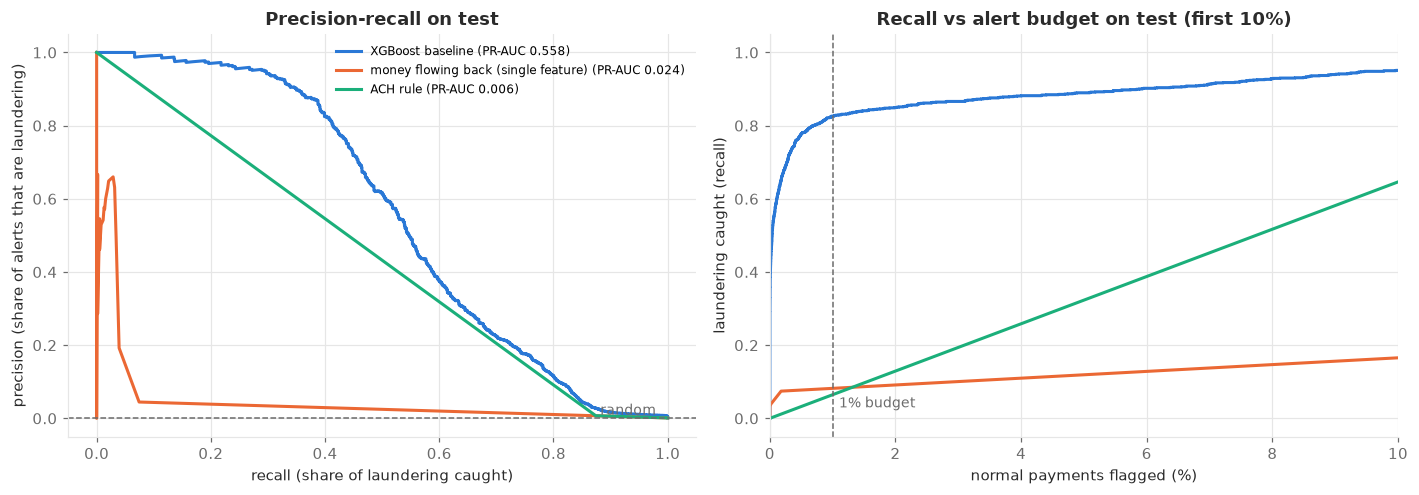

In [37]:
test_refs = {
    "XGBoost baseline": score_test,
    "money flowing back (single feature)": test["pair_reverse_prior_cnt"].to_numpy(dtype=float),
    "ACH rule": (test["payment_format_code"] == ACH).astype(float).to_numpy(),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for (name, s), color in zip(test_refs.items(), SERIES):
    p, r, _ = precision_recall_curve(y_test, s)
    axes[0].plot(r, p, color=color, label=f"{name} (PR-AUC {average_precision_score(y_test, s):.3f})")
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[1].plot(fpr * 100, tpr, color=color, label=name)
axes[0].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
axes[0].text(0.98, y_test.mean(), "random", color=MUTED, ha="right", va="bottom", fontsize=9)
axes[0].set_xlabel("recall (share of laundering caught)")
axes[0].set_ylabel("precision (share of alerts that are laundering)")
axes[0].set_title("Precision-recall on test")
axes[0].legend(loc="upper right", fontsize=8)
axes[1].axvline(1, color=MUTED, linestyle="--", linewidth=1)
axes[1].text(1.1, 0.03, "1% budget", color=MUTED, fontsize=9)
axes[1].set_xlim(0, 10)
axes[1].set_xlabel("normal payments flagged (%)")
axes[1].set_ylabel("laundering caught (recall)")
axes[1].set_title("Recall vs alert budget on test (first 10%)")
plt.tight_layout()
save(fig, FIG, "07_baseline_test_curves")
plt.show()

## Results within ACH and per laundering pattern


In [38]:
by_format = result.by_format
by_format

,pr_auc,roc_auc,random_pr_auc,laundering,recall_at_1pct,lift_over_random
ACH only,0.6368,0.9836,0.0072,999.0000,0.9680,88.1196
all other formats,0.0016,0.9442,0.0002,144.0000,0.0139,9.4890


In [39]:
per_pattern = result.by_pattern
if per_pattern is not None:
    print(f"Test laundering covered by named patterns: {int(per_pattern['transactions'].sum()):,} of {int(y_test.sum()):,}")
    display(per_pattern)
else:
    print("pattern_transactions.parquet not found; run `python main.py clean` with the Patterns file in data/raw/")

Test laundering covered by named patterns: 31 of 1,143


,attempts,transactions,recall_at_1pct,attempts_with_any_alert
pattern_type,,,,
GATHER-SCATTER,9,31,1.0000,1.0000


## The model relies on

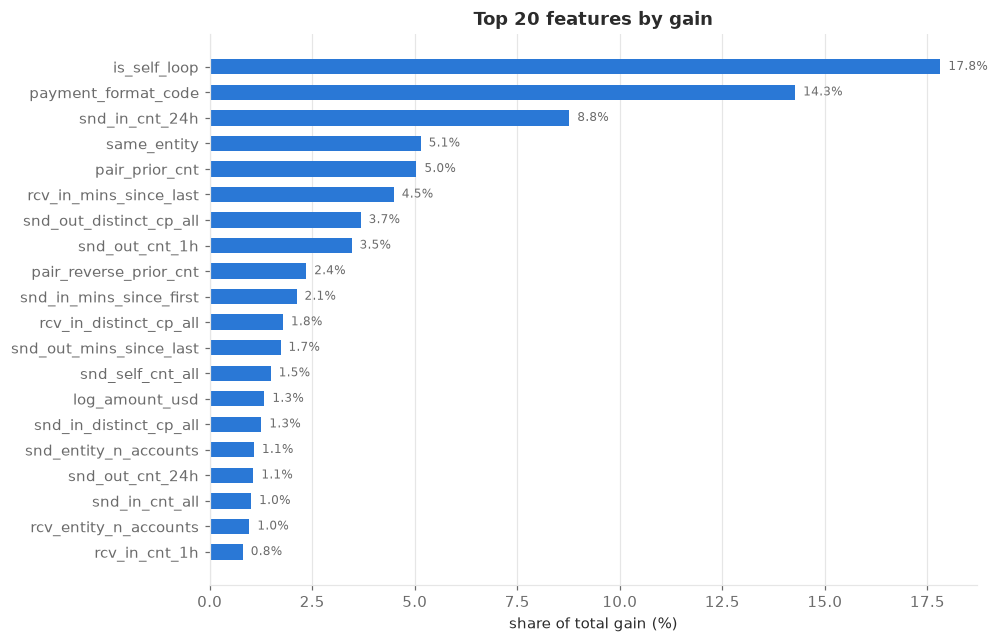

Top 10 features hold 67% of total gain; 0 features are never used.


In [40]:
gain_share = result.gain_share

top = gain_share.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.values * 100, color=NORMAL, height=0.6)
for y, v in enumerate(top.values * 100):
    ax.text(v, y, f"  {v:.1f}%", va="center", color=MUTED, fontsize=8)
ax.set_xlabel("share of total gain (%)")
ax.set_title("Top 20 features by gain")
ax.grid(axis="y", visible=False)
save(fig, FIG, "08_baseline_feature_importance")
plt.show()
print(f"Top 10 features hold {gain_share.head(10).sum():.0%} of total gain; "
      f"{(gain_share == 0).sum()} features are never used.")

## What it misses


In [41]:
test_eval = test[["tx_id", "payment_format_code", "pair_prior_cnt", "pair_reverse_prior_cnt",
                  "snd_out_cnt_all", "log_amount_usd", "is_laundering"]].copy()
test_eval["score"] = score_test
test_eval["flagged"] = score_test >= thresholds[0.01]
inv_formats = {v: k for k, v in format_codes.items()}
test_eval["payment_format"] = test_eval["payment_format_code"].map(inv_formats)

laund = test_eval[test_eval["is_laundering"] == 1]
missed_by_format = laund.groupby("payment_format").agg(
    laundering=("flagged", "size"), caught=("flagged", "sum"))
missed_by_format["recall"] = missed_by_format["caught"] / missed_by_format["laundering"]
missed_by_format.sort_values("laundering", ascending=False)

,laundering,caught,recall
payment_format,,,
ACH,999,967,0.9680
Cheque,71,1,0.0141
Credit Card,38,0,0.0000
Cash,22,0,0.0000
Bitcoin,13,1,0.0769


In [42]:
laund.assign(outcome=np.where(laund["flagged"], "caught", "missed")).groupby("outcome").agg(
    transactions=("tx_id", "size"),
    first_time_pair=("pair_prior_cnt", lambda s: (s == 0).mean()),
    money_flowing_back=("pair_reverse_prior_cnt", lambda s: (s > 0).mean()),
    sender_history_median=("snd_out_cnt_all", "median"),
    median_log_amount=("log_amount_usd", "median"),
)

,transactions,first_time_pair,money_flowing_back,sender_history_median,median_log_amount
outcome,,,,,
caught,969,0.9154,0.0805,3.0000,8.8213
missed,174,0.1149,0.0402,"19,879.5000",7.2272


## Saving the model and metrics

In [43]:
paths.models_dir.mkdir(exist_ok=True)
model_path = paths.models_dir / "xgb_baseline.json"
model.save_model(model_path)
metrics_path = paths.reports_dir / "metrics_step3_baseline.json"
write_json(metrics_record(result, splits, config.baseline), metrics_path)
print(f"Saved {model_path.relative_to(ROOT)} and {metrics_path.relative_to(ROOT)}")

Saved models\xgb_baseline.json and reports\metrics_step3_baseline.json


## Findings



In [44]:
h, a = headline, by_format.loc["ACH only"]
lines = [
    f"- **Test PR-AUC {h['pr_auc']:.3f}** vs {h['random_pr_auc']:.4f} for random "
    f"({h['pr_auc'] / h['random_pr_auc']:.0f}x), ROC-AUC {h['roc_auc']:.3f}.",
    f"- **At a 1% alert budget** (threshold fixed on validation) the model catches "
    f"**{h['recall_at_1pct']:.1%}** of test laundering; {h['precision_at_1pct']:.2%} of alerts are laundering "
    f"(realised FPR {h['fpr_at_1pct']:.2%}, {h['alerts_at_1pct'] / test_days:,.0f} alerts/day).",
    f"- **Threshold drift**: the 1% budget fixed on validation flags {h['fpr_at_1pct']:.2%} of normal test "
    f"payments, so alert volume needs monitoring and thresholds need re-setting as traffic changes.",
    f"- **Within ACH only**: PR-AUC {a['pr_auc']:.3f} vs {a['random_pr_auc']:.4f} random "
    f"({a['lift_over_random']:.0f}x), so the model learns more than the payment format.",
    f"- **Most important features**: {', '.join(gain_share.head(5).index)}.",
]
if per_pattern is not None and len(per_pattern) > 1:
    best, worst = per_pattern["recall_at_1pct"].idxmax(), per_pattern["recall_at_1pct"].idxmin()
    lines.append(f"- **By pattern**: highest recall on {best} ({per_pattern.loc[best, 'recall_at_1pct']:.0%}), "
                 f"lowest on {worst} ({per_pattern.loc[worst, 'recall_at_1pct']:.0%}).")
elif per_pattern is not None:
    lines.append(f"- **By pattern**: only {int(per_pattern['transactions'].sum())} test laundering transactions "
                 f"belong to a named pattern ({', '.join(per_pattern.index)}), too few for per-pattern conclusions.")
o = by_format.loc["all other formats"]
lines.append(f"- **Outside ACH the model barely works**: PR-AUC {o['pr_auc']:.4f}, recall "
             f"{o['recall_at_1pct']:.1%} at the 1% budget ({int(o['laundering'])} laundering transactions).")
lines.append("- **Next (step 4)**: add graph features (degree, PageRank, cycles) and measure the gain "
             "over these exact numbers on the same test set.")
display(Markdown("\n".join(lines)))

- **Test PR-AUC 0.558** vs 0.0011 for random (496x), ROC-AUC 0.987.
- **At a 1% alert budget** (threshold fixed on validation) the model catches **84.8%** of test laundering; 4.82% of alerts are laundering (realised FPR 1.88%, 8,633 alerts/day).
- **Threshold drift**: the 1% budget fixed on validation flags 1.88% of normal test payments, so alert volume needs monitoring and thresholds need re-setting as traffic changes.
- **Within ACH only**: PR-AUC 0.637 vs 0.0072 random (88x), so the model learns more than the payment format.
- **Most important features**: is_self_loop, payment_format_code, snd_in_cnt_24h, same_entity, pair_prior_cnt.
- **By pattern**: only 31 test laundering transactions belong to a named pattern (GATHER-SCATTER), too few for per-pattern conclusions.
- **Outside ACH the model barely works**: PR-AUC 0.0016, recall 1.4% at the 1% budget (144 laundering transactions).
- **Next (step 4)**: add graph features (degree, PageRank, cycles) and measure the gain over these exact numbers on the same test set.